# 🌐 Topic 1: Multi-Agent Network Collaboration (Peer-to-Peer RAG)
### Decentralized Multi-Agent Coordination via LangGraph `Command` and Shared `MessagesState`

---

## 📌 Architectural Overview
In a **Multi-Agent Network** (Peer-to-Peer Collaboration), specialized agents collaborate as equal peers without a centralized manager directing every single step. Control is passed dynamically between agents using LangGraph's `Command(goto=..., update=...)`.

### Key Characteristics:
- **Decentralized Handoffs:** Agents inspect the state and determine which peer should take over next.
- **Shared Memory:** All agents operate on a unified `MessagesState`, preserving the full conversation and tool trajectory.
- **Role Specialization:**
  1. **🔍 Researcher Agent:** Uses vector retrieval (`InternalResearchNotes` over internal benchmark logs) and real-time web search (`TavilySearch`) to gather empirical data.
  2. **✍️ Blog Writer Agent:** Synthesizes the raw research findings into a structured, production-grade Markdown blog post, concluding with a `FINAL ANSWER` stop token.

---

### 🎨 Architecture Diagram
![Multi-Agent Network Architecture](images/multi_agent_network_architecture.png)


### 1. Environment & API Keys Setup
Loads API keys from the root `.env` file, suppresses OpenMP duplicate library warnings on Windows, and prevents HuggingFace hub network checks.

In [1]:
import os
import sys

# Suppress OpenMP runtime conflicts on Windows
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
# Use cached HuggingFace models offline without network stalls
os.environ["HF_HUB_OFFLINE"] = "1"

from dotenv import load_dotenv, find_dotenv

# Load keys (TAVILY_API_KEY, GROQ_API_KEY, OPENAI_API_KEY) from workspace root .env
load_dotenv(find_dotenv(usecwd=True))
sys.path.append(os.path.abspath(".."))

print("🔑 Environment Configuration:")
print("- TAVILY_API_KEY:", "✅ Configured" if os.getenv("TAVILY_API_KEY") else "❌ Missing")
print("- GROQ_API_KEY:  ", "✅ Configured" if os.getenv("GROQ_API_KEY") else "❌ Missing")
print("- OPENAI_API_KEY:", "✅ Configured" if os.getenv("OPENAI_API_KEY") else "❌ Missing")

🔑 Environment Configuration:
- TAVILY_API_KEY: ✅ Configured
- GROQ_API_KEY:   ✅ Configured
- OPENAI_API_KEY: ✅ Configured


### 2. Centralized LLM Initialization
Initializes the chat model using `llm_config.get_llm()`, configured with automatic zero-downtime failover across verified free Groq models.

In [2]:
from llm_config import get_llm

# Initialize primary reasoning model with zero-downtime fallback
llm = get_llm(temperature=0.1)
test_greeting = llm.invoke("Hello! In one sentence, what makes multi-agent systems powerful?")
print("🤖 LLM Response:", test_greeting.content.strip())

🤖 LLM Response: Multi-agent systems are powerful because they enable complex problem-solving through the parallelization of tasks, specialized division of labor, and collaborative reasoning among autonomous entities.


### 3. RAG Knowledge Base & Tools Setup
Builds two specialized tools for the Researcher Agent:
1. **`InternalResearchNotes`:** FAISS vector store indexing `data/research_notes.txt` using local embeddings (`sentence-transformers/all-MiniLM-L6-v2`).
2. **`TavilySearch`:** Live web retrieval for real-time external data.

In [3]:
from pydantic import BaseModel, Field
from langchain_core.tools import StructuredTool
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_tavily import TavilySearch

class RetrieverQueryInput(BaseModel):
    query: str = Field(description="Search query to retrieve empirical research notes and experimental data")

def make_retriever_tool_from_text(file_path: str, name: str, desc: str):
    # Dynamically resolve file location across repo directory structure
    possible_paths = [
        file_path,
        os.path.join("..", file_path),
        os.path.join("..", "data", os.path.basename(file_path)),
        os.path.join("data", os.path.basename(file_path)),
        os.path.join("..", "data", "research_notes.txt"),
        os.path.join("data", "research_notes.txt"),
    ]
    resolved_path = next((p for p in possible_paths if os.path.exists(p)), os.path.join("..", "data", "research_notes.txt"))
    print(f"📁 Loading Knowledge Base from: {resolved_path}")
    
    docs = TextLoader(resolved_path, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    
    # Fast, local, reliable embedding model
    emb = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        model_kwargs={"local_files_only": True}
    )
    vectorstore = FAISS.from_documents(chunks, emb)
    retriever = vectorstore.as_retriever(search_kwargs={"k": 2})

    def tool_func(query: str) -> str:
        print(f"📚 [Retriever Tool] Query: '{query}'")
        results = retriever.invoke(query)
        return "\n\n".join(doc.page_content for doc in results[:2])

    return StructuredTool.from_function(
        func=tool_func,
        name=name,
        description=desc,
        args_schema=RetrieverQueryInput
    )

# Internal RAG Tool
internal_tool_1 = make_retriever_tool_from_text(
    "research_notes.txt",
    "InternalResearchNotes",
    "Search internal research notes for experimental results, model evaluations, accuracy metrics, and benchmark data."
)

# External Web Search Tool
tavily_tool = TavilySearch(max_results=3)

print("✅ Tools successfully created:")
print("-", internal_tool_1.name)
print("-", tavily_tool.name)

C:\Users\itsar\AppData\Local\Temp\ipykernel_17284\1498700662.py:3: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import TextLoader
c:\RAG\Code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


📁 Loading Knowledge Base from: ..\data\research_notes.txt


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13573.80it/s]


✅ Tools successfully created:
- InternalResearchNotes
- tavily_search


### 4. Collaborative Prompts & Termination Protocol
In peer-to-peer collaboration, agents need a stop condition so they don't loop endlessly. We define:
- `make_system_prompt`: Injects collaborative guidelines and instructs the writer to prefix its response with `FINAL ANSWER` once complete.
- `get_next_node`: Checks if `FINAL ANSWER` is present; if so, routes to `END`.

In [4]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.graph import MessagesState, END
from langgraph.types import Command
from typing import Literal

def get_next_node(last_message: BaseMessage, default_goto: str):
    """Terminates the network when an agent outputs FINAL ANSWER."""
    if "FINAL ANSWER" in last_message.content:
        return END
    return default_goto

def make_system_prompt(suffix: str) -> str:
    return (
        "You are a helpful AI assistant collaborating with other specialist assistants.\n"
        "Use the provided tools to progress towards fulfilling the user request.\n"
        "If you are unable to fully answer, that is OK: your colleague with different capabilities will continue where you left off.\n"
        "Execute what you can to make progress.\n"
        "If you or any colleague have the final deliverable, prefix your response with FINAL ANSWER so the team knows to stop.\n\n"
        f"{suffix}"
    )

### 5. Peer Agents & Node Functions
We create two ReAct agents:
1. `research_agent`: Equipped with `[internal_tool_1, tavily_tool]`.
2. `blog_agent`: Equipped with synthesis instructions.

> **💡 Provider Compatibility Tip:** Not all LLM inference providers permit consecutive `AIMessage` turns in the history. To ensure universal compatibility across Groq, OpenAI, and Anthropic, each node converts its final AI output to a `HumanMessage(content=..., name="<agent_name>")` before passing state.


In [ ]:
from langgraph.prebuilt import create_react_agent

# 1. Researcher Agent
research_agent = create_react_agent(
    model=llm,
    tools=[internal_tool_1, tavily_tool],
    prompt=make_system_prompt(
        "You are a dedicated research specialist. Use InternalResearchNotes and TavilySearch to find factual information.\n"
        "Once you have gathered the relevant facts, summarize them clearly and pass them to your blog_generator colleague."
    ),
    name="researcher"
)

# Researcher Node Function
def research_node(state: MessagesState) -> Command[Literal["blog_generator", END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # Wrap the AI output in HumanMessage for provider safety
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content,name="researcher")
    return Command(update={"messages": result["messages"]},goto=goto)

# 2. Blog Writer Agent
blog_agent = create_react_agent(
    model=llm,
    tools=[],
    prompt=make_system_prompt(
        "You are an expert technical blog writer. You will receive research data from your researcher colleague.\n"
        "Synthesize the research into a well-structured, engaging Markdown blog post with introduction, key findings, and summary.\n"
        "When finished, MUST prefix your response with 'FINAL ANSWER' followed by the complete blog."
    ),
    name="blog_generator"
)

# Blog Generator Node Function
def blog_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = blog_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")

    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content,name="blog_generator")
    return Command(update={"messages": result["messages"]},goto=goto)

print("✅ Agents and Nodes initialized successfully.")

✅ Agents and Nodes initialized successfully.


C:\Users\itsar\AppData\Local\Temp\ipykernel_17284\765885098.py:4: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(
C:\Users\itsar\AppData\Local\Temp\ipykernel_17284\765885098.py:30: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent = create_react_agent(


### 6. Graph Assembly & Compilation
Connects the nodes into a cyclical `StateGraph(MessagesState)`. The graph begins at `researcher`, which delegates to `blog_generator`, and exits when `FINAL ANSWER` is reached.

In [6]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)

# Register peer nodes
workflow.add_node("researcher", research_node)
workflow.add_node("blog_generator", blog_node)

# Set starting entry point
workflow.add_edge(START, "researcher")

# Compile graph
network_app = workflow.compile()
print("✅ Multi-Agent Network compiled successfully!")

✅ Multi-Agent Network compiled successfully!


### 7. Visualizing the Multi-Agent Network Graph
Renders the compiled execution graph showing the start edge, peer nodes, and terminal transition.

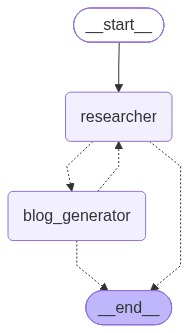

📊 Graph image saved to images/multi_agent_network_graph.png


In [7]:
from IPython.display import Image, display

# Display compiled LangGraph workflow
try:
    graph_png = network_app.get_graph().draw_mermaid_png()
    display(Image(graph_png))
    # Also save to images directory
    with open("images/multi_agent_network_graph.png", "wb") as f:
        f.write(graph_png)
    print("📊 Graph image saved to images/multi_agent_network_graph.png")
except Exception as e:
    print(f"Mermaid render note: {e}")
    try:
        print(network_app.get_graph().draw_ascii())
    except Exception:
        pass

### 8. End-to-End Execution
We run a complex query: *"Write a detailed blog post on transformer variants in production deployments based on internal research notes."*
Watch how the researcher retrieves internal facts and the blog generator compiles the complete post.

In [ ]:
user_query = "Write a detailed blog post on transformer variants evaluated in production deployments based on our internal notes."
print(f"🚀 Invoking Multi-Agent Network with Query:\n'{user_query}'\n" + "="*70)

response = network_app.invoke({
    "messages": [HumanMessage(content=user_query)]
})

print(f"\n🎯 Execution completed! Total messages in trajectory: {len(response['messages'])}\n")
final_content = response["messages"][-1].content
clean_blog = final_content.replace("FINAL ANSWER", "").strip()
print("="*70 + "\n📝 PUBLISHED BLOG DELIVERABLE:\n" + "="*70)
print(clean_blog)

### 9. Message Trajectory Analysis
Inspects the sequential conversation turns between the user, the researcher, and the blog writer.

In [ ]:
print("📜 Execution Trajectory Log:")
for i, msg in enumerate(response["messages"]):
    sender = getattr(msg, "name", "user") or msg.type
    content_preview = msg.content[:160].replace("\n", " ")
    print(f"[{i:02d}] {sender.upper():<16} : {content_preview}...")

### 10. Architectural Summary & Tradeoffs

| Aspect | Multi-Agent Network |
| :--- | :--- |
| **Control Flow** | Decentralized, peer-to-peer handoffs via `Command(goto=...)` |
| **Coordination** | Self-directed based on message state inspection |
| **Best For** | 2-3 collaborating specialists with sequential or co-creative workflows (e.g. Researcher + Writer, Coder + Reviewer) |
| **Advantages** | Simple to assemble, low overhead, high autonomy for each agent |
| **Limitations** | As agent count grows (>3), peer routing becomes complex and prone to circular ping-pong loops. For 4+ agents, use the **Supervisor Pattern** (Topic 2). |
